# 05: Genetic Algorithm vs CFLP (Phase 5)

This notebook reads the outputs of `python main.py genetic` and runs one short live GA on Puerto Rico.

In [1]:
import sys, os, pathlib
ROOT = pathlib.Path.cwd().resolve().parent if pathlib.Path.cwd().name == 'notebooks' else pathlib.Path.cwd().resolve()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import numpy as np, pandas as pd
from IPython.display import Image, display
pd.set_option('display.width', 220, 'display.max_columns', 40, 'display.max_colwidth', 60)
OUT = ROOT / 'data/outputs'
from src.warehouse_cflp import build_problem, solve_cflp
from src.genetic_algorithm import run_ga, search_space
display(pd.read_csv(OUT / 'warehouse_algorithm_comparison.csv')[['network','method','n_open','total_cost','opening_cost','transport_cost','avg_distance_km_order_weighted','mean_utilization','unserved_units','feasible','gap_vs_cflp_pct','runtime_s']])

,network,method,n_open,total_cost,opening_cost,transport_cost,avg_distance_km_order_weighted,mean_utilization,unserved_units,feasible,gap_vs_cflp_pct,runtime_s
0,CONUS,CFLP (exact MILP),6.0,18497.264009,9000.0,9348.360207,334.467270,0.620433,0.0,True,0.000000,0.928488
1,CONUS,Genetic Algorithm (best of seeds),6.0,18604.638822,9000.0,9455.735019,338.308945,0.620433,0.0,True,0.580490,70.603416
2,CONUS,K-Means (k=6),6.0,18655.349629,9000.0,9506.445826,340.123285,0.620433,0.0,True,0.854643,0.596728
3,CONUS,"Random (k=6, mean of 30)",6.0,30117.759525,9000.0,20968.855723,750.227396,0.620433,0.0,True,62.822780,23.618857
4,Puerto Rico,CFLP (exact MILP),2.0,2509.509655,2400.0,21.759655,1.239866,0.877500,0.0,True,0.000000,0.061431
5,Puerto Rico,Genetic Algorithm (best of seeds),2.0,2509.509655,2400.0,21.759655,1.239866,0.877500,0.0,True,0.000000,1.613275
6,Puerto Rico,K-Means (k=2),2.0,3206.387534,2400.0,718.637534,40.948008,0.877500,0.0,True,27.769484,0.059434
7,Puerto Rico,"Random (k=2, mean of 30)",2.0,3394.689126,2400.0,906.939126,51.677443,0.877500,0.0,True,35.273005,1.847870


,network,seed,n_open,total_cost,generations,unique_evaluations,runtime_s,search_space_size
0,CONUS,11,6,18856.987563,62,686,14.992374,2^37
1,CONUS,22,6,18750.771697,38,588,13.100641,2^37
2,CONUS,33,6,18942.042726,35,519,11.883436,2^37
3,CONUS,44,6,18910.921732,27,448,10.661756,2^37
4,CONUS,55,6,18604.638822,80,878,19.965209,2^37
5,Puerto Rico,11,2,2598.719977,49,368,0.324609,2^25
6,Puerto Rico,22,2,2509.509655,33,375,0.309546,2^25
7,Puerto Rico,33,2,2509.509655,37,329,0.276578,2^25
8,Puerto Rico,44,2,2509.509655,30,360,0.296396,2^25
9,Puerto Rico,55,2,2509.509655,45,391,0.406146,2^25


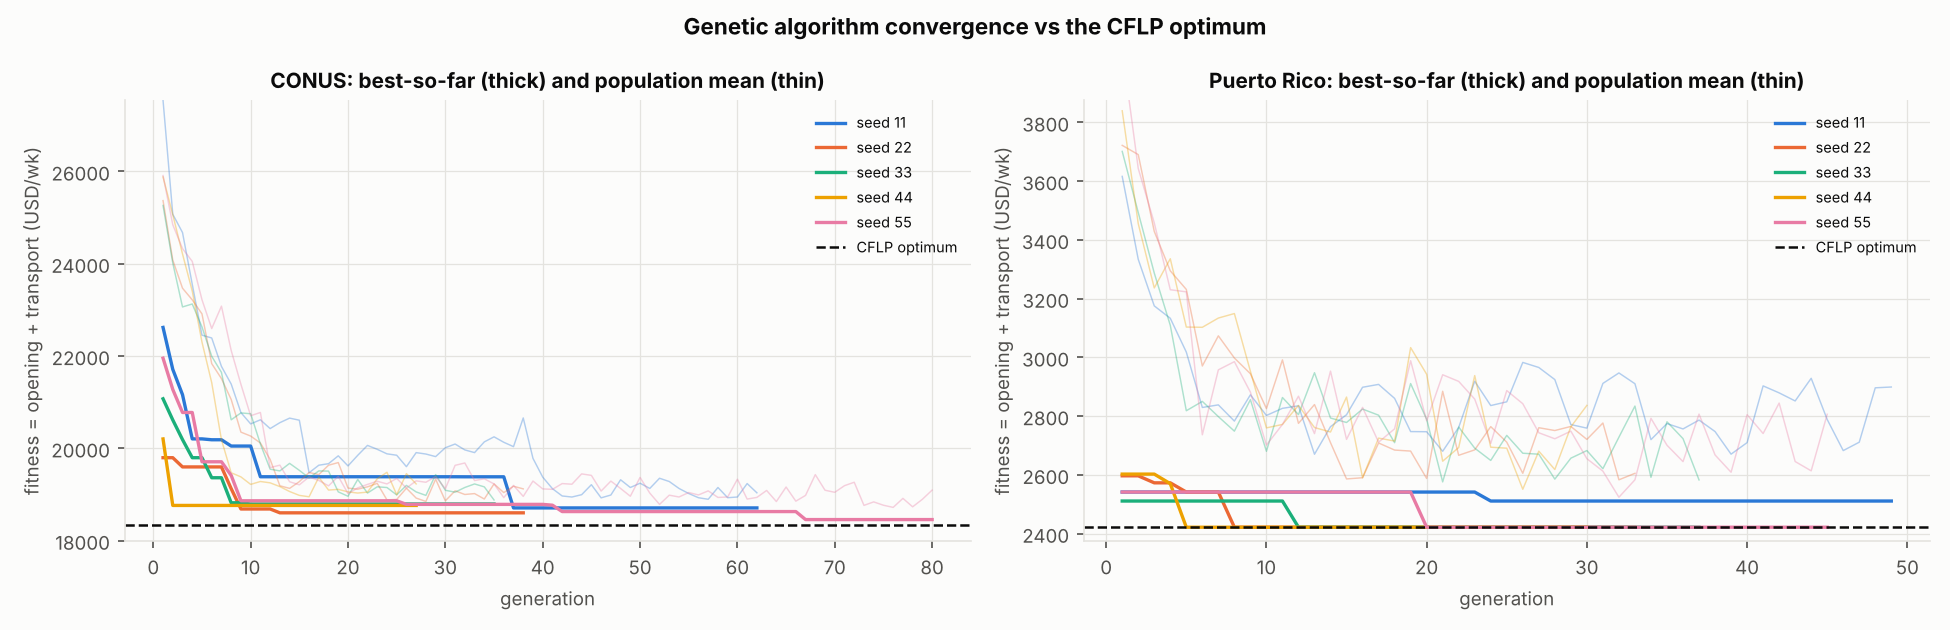

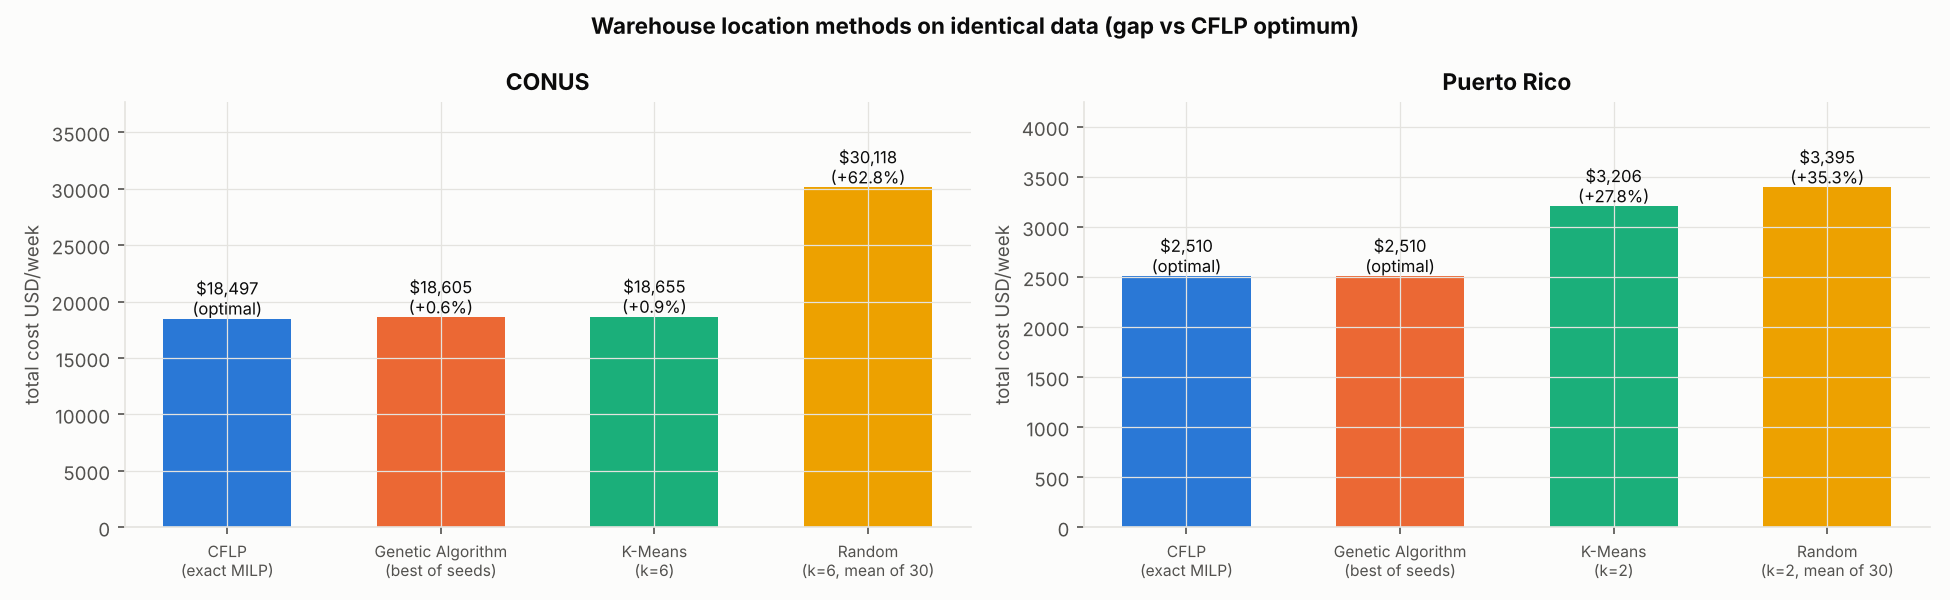

In [2]:
ga = pd.read_csv(OUT / 'genetic_algorithm_results.csv')
display(ga[['network','seed','n_open','total_cost','generations','unique_evaluations','runtime_s','search_space_size']])
display(Image('reports/figures/ga_convergence.png')); display(Image('reports/figures/phase5_warehouse_algorithm_comparison.png'))

## Live run (Puerto Rico, seed 11)

In [3]:
prob = build_problem('Puerto Rico')
r = run_ga(prob, 11)
exact = solve_cflp(prob, fixed_open=r.best_open)
opt = solve_cflp(prob)
print('search space:', search_space(prob), 'configurations | GA generations:', r.generations_run)
print('GA (exact allocation):', round(exact.objective, 2), '| CFLP optimum:', round(opt.objective, 2))

search space: 15250 configurations | GA generations: 49
GA (exact allocation): 2510.97 | CFLP optimum: 2421.76
